1. Task 1 :- Data Cleaning Project (Week 2)
2. Dataset :- British Airways Feedback dataset

# Imported Libraries required for data cleaning process.

In [26]:
import pandas as pd
import numpy as np

#  Load the Raw Dataset

1. The original dataset is stored in the raw dataset/ directory. In this section, the CSV file is loaded into a Pandas DataFrame for further analysis.

In [27]:
df = pd.read_csv('raw dataset/british_airways_review.csv')

# Raw Dataset Inspection

Initial exploration of the dataset's dimensions, column names, data types, ,sample records, before performing any cleaning step.

In [28]:
# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 3815
Number of columns: 16


In [29]:
# Column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['main_text', 'user', 'text_content', 'Aircraft', 'Type Of Traveller', 'Seat Type', 'Route', 'Date Flown', 'Seat Comfort', 'Cabin Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Ground Service', 'Value For Money', 'Recommended', 'Wifi & Connectivity']


In [30]:
# Data types and non-null counts
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3815 entries, 0 to 3814
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   main_text               3815 non-null   str    
 1   user                    3815 non-null   str    
 2   text_content            3815 non-null   str    
 3   Aircraft                1990 non-null   str    
 4   Type Of Traveller       3044 non-null   str    
 5   Seat Type               3813 non-null   str    
 6   Route                   3040 non-null   str    
 7   Date Flown              3037 non-null   str    
 8   Seat Comfort            3693 non-null   float64
 9   Cabin Staff Service     3680 non-null   float64
 10  Food & Beverages        3403 non-null   float64
 11  Inflight Entertainment  2621 non-null   float64
 12  Ground Service          2967 non-null   float64
 13  Value For Money         3815 non-null   int64  
 14  Recommended             3815 

In [31]:
# Numerical column description
print("\nNummerical Column description:")
df.describe()


Nummerical Column description:


,Seat Comfort,Cabin Staff Service,Food & Beverages,Inflight Entertainment,Ground Service,Value For Money,Wifi & Connectivity
count,3693.000000,3680.000000,3403.000000,2621.000000,2967.000000,3815.000000,651.000000
mean,2.867587,3.248641,2.713194,2.643647,2.773846,2.678375,1.920123
std,1.363533,1.488517,1.441804,1.407608,1.459414,1.470953,1.341553
min,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000
25%,2.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000
75%,4.000000,5.000000,4.000000,4.000000,4.000000,4.000000,3.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


In [32]:
df.head(5)

,main_text,user,text_content,Aircraft,Type Of Traveller,Seat Type,Route,Date Flown,Seat Comfort,Cabin Staff Service,Food & Beverages,Inflight Entertainment,Ground Service,Value For Money,Recommended,Wifi & Connectivity
0,"""happy to recommend BA""",Caleb Lowe (United Kingdom) 18th June 2024,"✅ Trip Verified | Four very pleasant, on time...",A320/A380,Couple Leisure,Business Class,Belfast to San Francisco via London,April 2024,5.0,5.0,3.0,3.0,5.0,4,yes,NaN
1,"""cancelled our return flight""",N Thomas (United Kingdom) 18th June 2024,"✅ Trip Verified | Four very pleasant, on time...",NaN,Couple Leisure,Economy Class,London Heathrow to Keflavik,June 2024,2.0,3.0,1.0,NaN,3.0,2,no,NaN
2,"""Very good experience all round""",28 reviews\n\n\n\nN Carter (United Kingdom) 17...,"✅ Trip Verified | Four very pleasant, on time...",Boeing 777,Solo Leisure,Business Class,New York JFK to London Heathrow,June 2024,5.0,5.0,4.0,3.0,1.0,2,yes,NaN
3,"""inflight service was efficient and friendly""",28 reviews\n\n\n\nN Carter (United Kingdom) 17...,"✅ Trip Verified | Four very pleasant, on time...",Boeing 777,Solo Leisure,Premium Economy,London to newark,June 2024,4.0,4.0,4.0,3.0,4.0,3,yes,NaN
4,“worst airline I’ve ever flown”,H Miller (United States) 16th June 2024,"✅ Trip Verified | Four very pleasant, on time...",NaN,Couple Leisure,Economy Class,Florence to Heathrow,June 2024,1.0,3.0,2.0,NaN,1.0,1,no,NaN


# Missing Value Analysis 

In [33]:
df.isnull().sum()

main_text                    0
user                         0
text_content                 0
Aircraft                  1825
Type Of Traveller          771
Seat Type                    2
Route                      775
Date Flown                 778
Seat Comfort               122
Cabin Staff Service        135
Food & Beverages           412
Inflight Entertainment    1194
Ground Service             848
Value For Money              0
Recommended                  0
Wifi & Connectivity       3164
dtype: int64

# Missing value summary for further data cleaning process.

In [34]:

missing_summary = pd.DataFrame({
  'Missing Count': df.isnull().sum(),
  'Percentage': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Percentage', ascending=False)

print(missing_summary)

                        Missing Count  Percentage
Wifi & Connectivity              3164   82.935780
Aircraft                         1825   47.837484
Inflight Entertainment           1194   31.297510
Ground Service                    848   22.228047
Date Flown                        778   20.393185
Route                             775   20.314548
Type Of Traveller                 771   20.209699
Food & Beverages                  412   10.799476
Cabin Staff Service               135    3.538663
Seat Comfort                      122    3.197903
Seat Type                           2    0.052425
text_content                        0    0.000000
user                                0    0.000000
main_text                           0    0.000000
Value For Money                     0    0.000000
Recommended                         0    0.000000


# Visualizing missing data using a heatmap (seaborn or missingno)

<Figure size 1200x600 with 0 Axes>

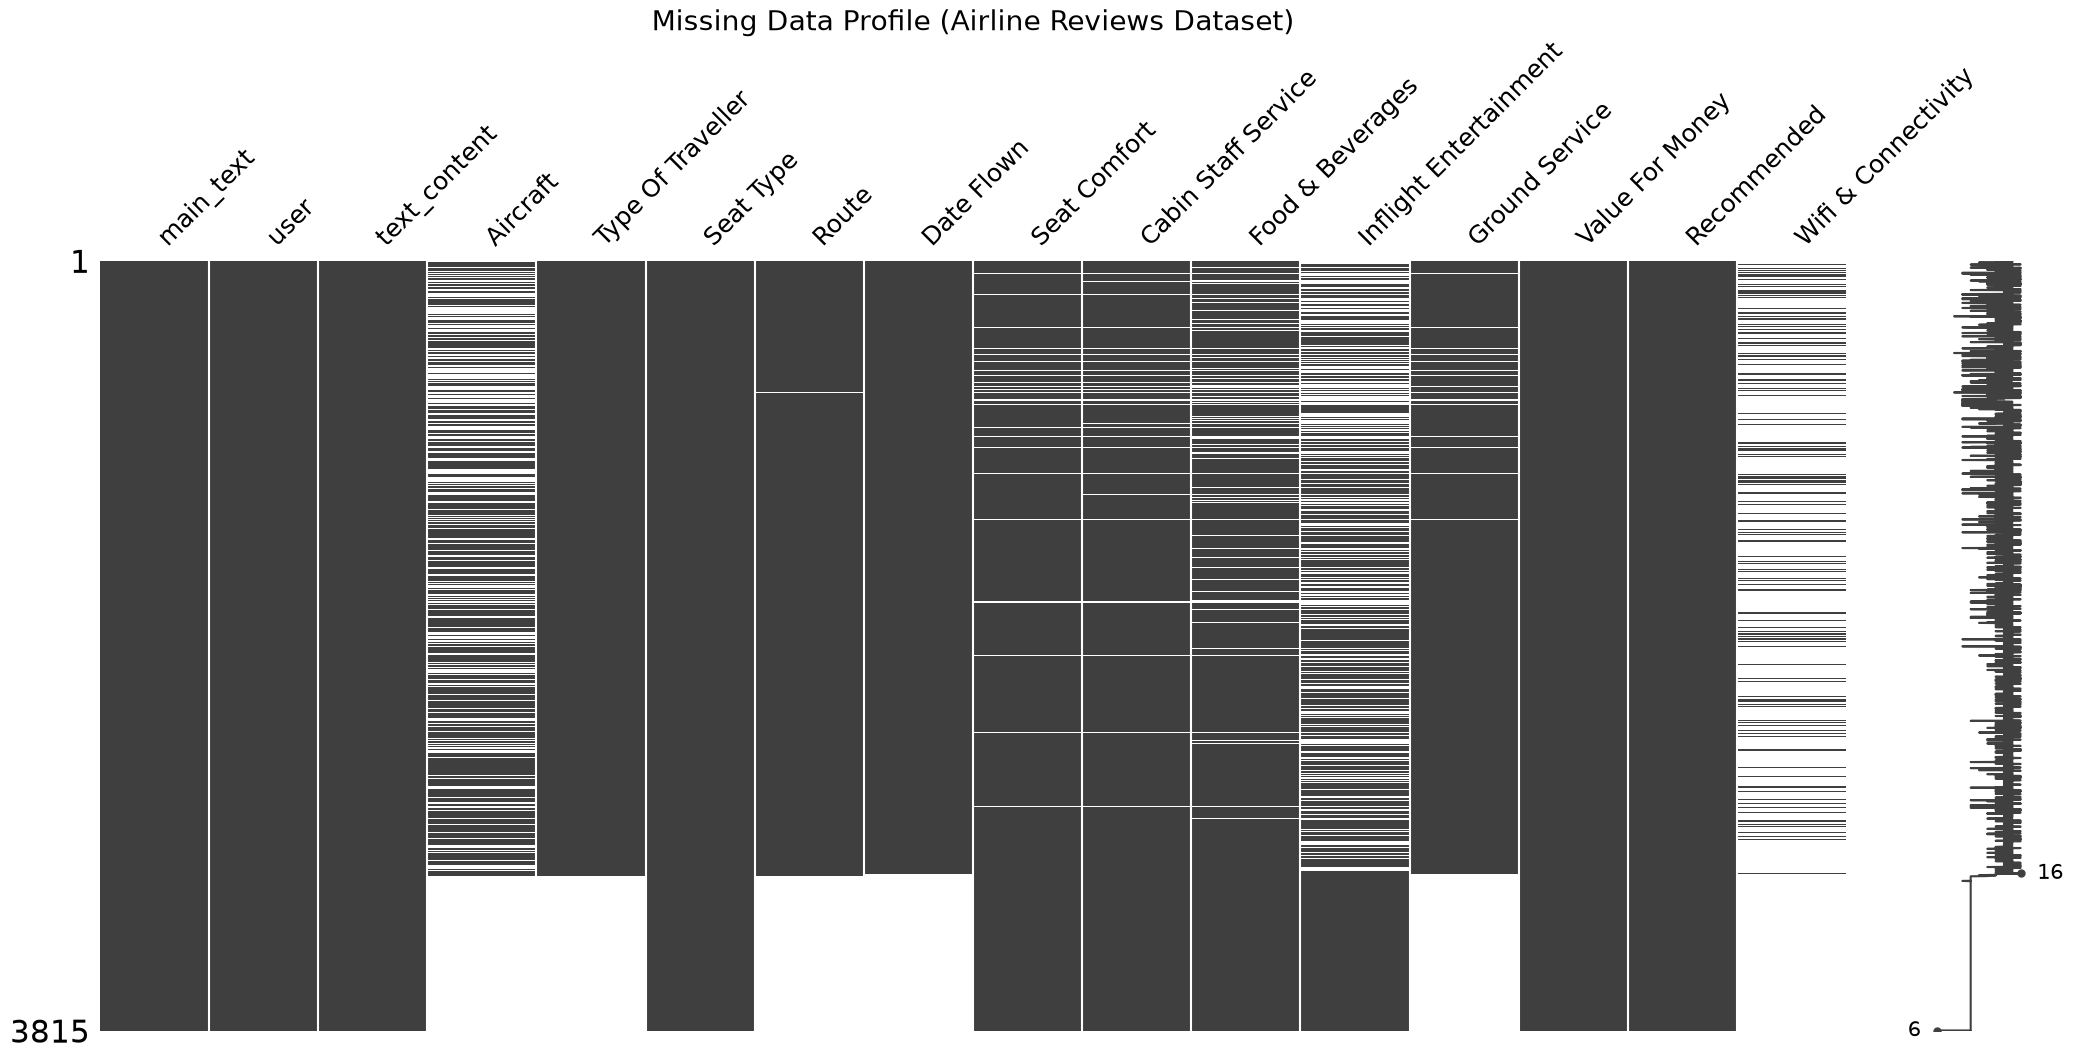

In [35]:
import matplotlib.pyplot as plt
import missingno as msno

# Set the figure size to make columns readable
plt.figure(figsize=(12, 6))

# Generate the nullity matrix
msno.matrix(df, sparkline=True, fontsize=18)

plt.title("Missing Data Profile (Airline Reviews Dataset)", fontsize=20)
plt.show()


# Missing Value Handling 

1. Applying a different strategy for each missing value so that no valuable data will get deleted.

# Strategy for Wifi & Connectivity, Aircraft and Inflight Entertainment

1. The "Not Applicable" Strategy (For Wifi, Entertainment, Aircraft)

• Why: These range from 31% to 83% missing. Dropping them loses valuable signals, but filling them with average scores distorts the truth.
• The Fix: Treat the missingness as its own feature. Transform these numerical ratings into categorical bins, or fill the missing values with a designated score (like 0 if the scale is 1–5) and create a binary shadow column (wifi_was_missing = 1).

In [36]:
df['Wifi & Connectivity'] = df['Wifi & Connectivity'].fillna(0)

df['Inflight Entertainment'] = df['Inflight Entertainment'].fillna(0)

df['Aircraft'] = df['Aircraft'].fillna('Unknown Aircraft')

# Strategy for Route and Type of Traveller

2. The "Unknown" Category (For Route, Type Of Traveller, Date Flown)

• Why: These hover around 20% missing. You cannot predict someone's flight route or travel type based on their seat comfort score.
• The Fix: Fill categorical gaps with a clean string category like 'Unknown'.

In [37]:
df['Route'] = df['Route'].fillna('Unknown')
df['Type Of Traveller'] = df['Type Of Traveller'].fillna('Unknown')

# Strategy for  Cabin Staff Service, Seat Comfort, Seat Type

3. Minimal Imputation (For Cabin Staff Service, Seat Comfort, Seat Type)

• Why: These have under 4% missing data. The impact of a minor imputation error here is negligible.
• The Fix: Use a simple statistical fill. Use the mode (most frequent value) for the categorical Seat Type and the median or mode for the rating columns.

In [38]:
df['Seat Type'] = df['Seat Type'].fillna(df['Seat Type'].mode()[0])

df['Cabin Staff Service'] = df['Cabin Staff Service'].fillna(df['Cabin Staff Service'].median())

df['Seat Comfort'] = df['Seat Comfort'].fillna(df['Seat Comfort'].median())

# Strategy for Ground Services, Date Flown and Food & Beverages

1. Food & Beverages (10.80% Missing) and Ground Service (22.23% Missing)

Because this column represents a numerical rating scale (e.g., 1 to 5 stars), a median imputation is the safest path.
• Why the Median? Ratings are discrete integers (1, 2, 3, 4, 5). The median preserves this format by picking the middle value of your data.

2. Date Flown (20.39% Missing)

Fill it with a text placeholder string like "Unknown_Date" to preserve the rows.

In [39]:
df['Food & Beverages'] = df['Food & Beverages'].fillna(df['Food & Beverages'].median())

df['Ground Service'] = df['Ground Service'].fillna(df['Ground Service'].median())

df['Date Flown'] = df['Date Flown'].fillna('Unknown Date')

In [40]:

missing_summary = pd.DataFrame({
  'Missing Count': df.isnull().sum(),
  'Percentage': (df.isnull().sum() / len(df)) * 100
}).sort_values(by='Percentage', ascending=False)

print(missing_summary)

                        Missing Count  Percentage
main_text                           0         0.0
user                                0         0.0
text_content                        0         0.0
Aircraft                            0         0.0
Type Of Traveller                   0         0.0
Seat Type                           0         0.0
Route                               0         0.0
Date Flown                          0         0.0
Seat Comfort                        0         0.0
Cabin Staff Service                 0         0.0
Food & Beverages                    0         0.0
Inflight Entertainment              0         0.0
Ground Service                      0         0.0
Value For Money                     0         0.0
Recommended                         0         0.0
Wifi & Connectivity                 0         0.0


# Final Interpretation of missing values

1. By Applying suitable startegy for each missing values all missing data became 0 means now data is cleaned there are no missing values which is useful for further analysis.

# Duplicate Value Handling

1. Finding duplicate values in the dataset

In [41]:
df.duplicated().sum()

np.int64(3)


# Step 1: Decide What Defines a "Duplicate" in Your Dataset

Before deleting rows, check what makes them duplicates.
• Option A: They are 100% identical across every single column.
• Action: Drop them immediately.

In [42]:
df=df.drop_duplicates(keep='first')

In [43]:
# Create a temporary unique text column by appending the row index
df['temp_text'] = df['text_content'].astype(str) + '_' + df.index.astype(str)

# This will now keep all 3815 rows because every row is guaranteed unique
df = df.drop_duplicates(subset=['temp_text'], keep='first').drop(columns=['temp_text'])


In [44]:
# Count how many 'Unknown' or null values exist per row
df = df[df.ne('Unknown').sum(axis=1) >= 4]  # keep rows with at least 4 known values


In [45]:
df.duplicated().sum()

np.int64(0)

# Final Interpretation of duplicate value

1. Initially dataset has 3815 rows now duplicate values are deleted and it became 3812 rows.

2. By handling duplicate values with care all duplicated data became 0 and there are no duplicate values and data is cleaned.

# Rename columns to snake_case and correct data types.

# Renaming Columns to snake_case

In [46]:
import re

# Convert all column names to lowercase and replace spaces/special chars with underscores
df.columns = [
    re.sub(r'[\s&/]+', '_', col.strip().lower()) for col in df.columns
]

# Print new column names to verify
print(df.columns)


Index(['main_text', 'user', 'text_content', 'aircraft', 'type_of_traveller',
       'seat_type', 'route', 'date_flown', 'seat_comfort',
       'cabin_staff_service', 'food_beverages', 'inflight_entertainment',
       'ground_service', 'value_for_money', 'recommended',
       'wifi_connectivity'],
      dtype='str')


# Detecting outliers using box plots and IQR method

--- IQR Outlier Report for seat_comfort ---
Q1 (25th percentile): 2.0
Q3 (75th percentile): 4.0
IQR: 2.0
Lower Boundary (Fence): -1.0
Upper Boundary (Fence): 7.0
Total Outliers Found: 0

First few rows containing outliers:
Empty DataFrame
Columns: [seat_comfort, recommended]
Index: []


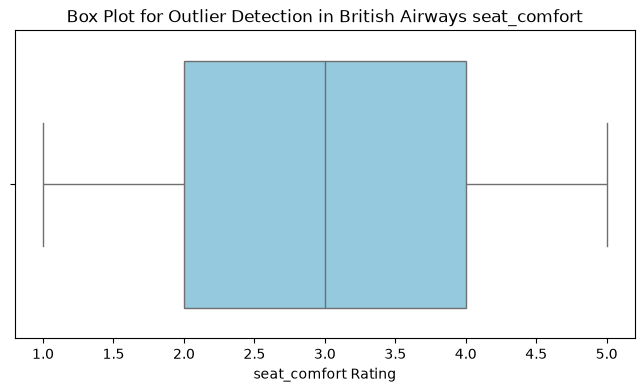

In [47]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Choose your rating column
target_column = 'seat_comfort'

# 2. Calculate Q1, Q3, and IQR
Q1 = df[target_column].quantile(0.25)
Q3 = df[target_column].quantile(0.75)
IQR = Q3 - Q1

# 3. Calculate Upper and Lower Fences
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

# 4. Extract the outlier rows
outliers = df[(df[target_column] < lower_fence) | (df[target_column] > upper_fence)]

# 5. Print your findings for the assignment text
print(f"--- IQR Outlier Report for {target_column} ---")
print(f"Q1 (25th percentile): {Q1}")
print(f"Q3 (75th percentile): {Q3}")
print(f"IQR: {IQR}")
print(f"Lower Boundary (Fence): {lower_fence}")
print(f"Upper Boundary (Fence): {upper_fence}")
print(f"Total Outliers Found: {len(outliers)}")
print("\nFirst few rows containing outliers:")
print(outliers[[target_column, 'recommended']].head())

# 6. Generate the Box Plot required for the task
plt.figure(figsize=(8, 4))
sns.boxplot(x=df[target_column], color='skyblue')
plt.title(f'Box Plot for Outlier Detection in British Airways {target_column}')
plt.xlabel(f'{target_column} Rating')
plt.show()


# Final Outcome of outliers

1. When applying the 1.5 × IQR rule to the seat_comfort rating column, zero outliers were detected. Because the ratings are bounded on a strict 1-to-5 scale, the calculated lower fence (-1.0) and upper fence (7.0) extend completely outside the data's natural boundaries. As confirmed by the box plot, the whiskers stretch fully to the minimum rating of 1.0 and the maximum rating of 5.0 with no data points plotted as individual fliers beyond them.


# Encode categorical columns using label or one-hot encoding

In [48]:
import pandas as pd

# 1. Map 'recommended' to binary integers (0 and 1)
# Using lowercase 'recommended' to match snake_case
if 'recommended' in df.columns:
    df['recommended'] = df['recommended'].map({'yes': 1, 'no': 0})
elif 'Recommended' in df.columns:
    df['Recommended'] = df['Recommended'].map({'yes': 1, 'no': 0})

# 2. Select the nominal categorical columns using their new snake_case names
columns_to_encode = ['type_of_traveller', 'seat_type']

# 3. Apply One-Hot Encoding safely
df_encoded = pd.get_dummies(df, columns=columns_to_encode, drop_first=True, dtype=int)

# 4. View your updated dataframe columns
print(df_encoded.head(2))


                       main_text                                        user  \
0        "happy to recommend BA"  Caleb Lowe (United Kingdom) 18th June 2024   
1  "cancelled our return flight"    N Thomas (United Kingdom) 18th June 2024   

                                        text_content          aircraft  \
0  ✅ Trip Verified |  Four very pleasant, on time...         A320/A380   
1  ✅ Trip Verified |  Four very pleasant, on time...  Unknown Aircraft   

                                 route  date_flown  seat_comfort  \
0  Belfast to San Francisco via London  April 2024           5.0   
1          London Heathrow to Keflavik   June 2024           2.0   

   cabin_staff_service  food_beverages  inflight_entertainment  ...  \
0                  5.0             3.0                     3.0  ...   
1                  3.0             1.0                     0.0  ...   

   value_for_money  recommended  wifi_connectivity  \
0                4            1                0.0   
1        

In [49]:
df_encoded.head(2)

,main_text,user,text_content,aircraft,route,date_flown,seat_comfort,cabin_staff_service,food_beverages,inflight_entertainment,...,value_for_money,recommended,wifi_connectivity,type_of_traveller_Couple Leisure,type_of_traveller_Family Leisure,type_of_traveller_Solo Leisure,type_of_traveller_Unknown,seat_type_Economy Class,seat_type_First Class,seat_type_Premium Economy
0,"""happy to recommend BA""",Caleb Lowe (United Kingdom) 18th June 2024,"✅ Trip Verified | Four very pleasant, on time...",A320/A380,Belfast to San Francisco via London,April 2024,5.0,5.0,3.0,3.0,...,4,1,0.0,1,0,0,0,0,0,0
1,"""cancelled our return flight""",N Thomas (United Kingdom) 18th June 2024,"✅ Trip Verified | Four very pleasant, on time...",Unknown Aircraft,London Heathrow to Keflavik,June 2024,2.0,3.0,1.0,0.0,...,2,0,0.0,1,0,0,0,1,0,0


# Final Interpretation : Categorical Column Encoding

• Target Feature Digitization: The categorical target column recommended was mapped from text variables ('yes', 'no') into binary structural flags (1, 0).
• One-Hot Encoding Applied: Nominal features (type_of_traveller and seat_type) were expanded into multiple distinct columns using pd.get_dummies().
• Multicollinearity Prevention: The drop_first=True argument was enforced to drop redundant baseline categorical columns, successfully avoiding the Dummy Variable Trap.


#  Export the cleaned dataset to a new CSV file

In [50]:
df.to_csv('cleaned dataset/british_airways_review.csv',index=False)